# [Bonus Tasks](svm_segm.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(1, 0.4, 0.7)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [3]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

We want to divide an image into smaller patches of 32 × 32 pixels

The SVM cannot directly work with a two-dimensional image patch. Instead, we convert each patch into a one-dimensional row containing all 1024 pixel intensities

In [4]:
def create_data_matrix(img):
    patches = skimage.util.view_as_blocks(img, patch_sizes)
    X = patches.reshape(-1, patch_sizes[0] * patch_sizes[1])
    return X

view_as_blocks() divides the image into equally sized, non-overlapping blocks

->The resulting patches array has four dimensions: (number of patch rows, number of patch columns, 32, 32)

Then the patches are converted into the format required by the SVM

-> by changing the dimensions of an array without changing its underlying values (with reshape)


**[Task 1.2.]()** Implement `create_gt_labels_vector`:

The corresponding ground-truth labels

Every image patch gets a label depending on how much foreground (the object we want to segment) it contains

Possible labels:

- +1: Foreground – more than 50% of the patch is foreground.
- -1: Background – the patch contains no foreground pixels at all.
- 0: Mixed – the patch contains some foreground, but not more than 50%.

-> Some patches contain both background and foreground, e.g when an object is located at the edge of a patch, so they receive label 0

In [5]:
def create_gt_labels_vector(gt):
    patches = skimage.util.view_as_blocks(gt, patch_sizes)
    labels = []

    for patch in patches.reshape(-1, patch_sizes[0], patch_sizes[1]):
        foreground = patch.mean()

        if foreground > 0.5:
            labels.append(1)
        elif foreground == 0:
            labels.append(-1)
        else:
            labels.append(0)

    return np.array(labels)

First, I divide the binary ground-truth image into the same 32 × 32 patches as in Task 1 

Then I iterate over each patch and calculate the mean pixel intensity

Since the image is binary, this mean represents the fraction of foreground pixels 

Based on that fraction, I assign +1 if it is greater than 50%, -1 if there is no foreground, and 0 otherwise 

Finally, I return all labels as a NumPy array

**[Task 1.3.]()** Create the SVM classifier:

In [6]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

The pipeline first standardizes the data and then trains the SVM

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [7]:
img33 = plt.imread('data/NIH3T3/im/dna-33.png')
img44 = plt.imread('data/NIH3T3/im/dna-44.png')

X33 = create_data_matrix(img33)
X44 = create_data_matrix(img44)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [8]:
gt33 = plt.imread('data/NIH3T3/gt/33.png')
gt44 = plt.imread('data/NIH3T3/gt/44.png')

Y33 = create_gt_labels_vector(gt33)
Y44 = create_gt_labels_vector(gt44)

The important thing is that the order corresponds:
- X33[0] contains the pixel values of the first patch
- Y33[0] contains the label of that exact same patch

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [9]:
X = np.concatenate((X33, X44))
Y = np.concatenate((Y33, Y44))

valid = Y != 0

X = X[valid]
Y = Y[valid]

np.concatenate() joins multiple arrays along an existing axis. By default, it joins them along axis 0, meaning it adds the rows underneath each other

also i discarded the patches with the label 0

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [10]:
clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

Now that the classifier has been trained, i use it to segnement a image it has not been trained on

In [11]:
def predict_image(img):
    X = create_data_matrix(img)

    predictions = clf.predict(X)

    seg = predictions == 1

    seg = np.repeat(
        np.repeat(seg.reshape(-1, img.shape[1] // 32), 32, axis=0),
        32,
        axis=1
    )

    return seg

First, I use create_data_matrix to divide the input image into patches and convert them into a data matrix 

Then I use the trained SVM classifier to predict a label for each patch 

I compare the predictions with +1 to obtain a Boolean array, where True represents foreground and False represents background, since 0 has been discarded 

Finally, I reshape the predictions into the patch grid and expand each prediction to its original 32 × 32 pixel area to reconstruct the binary segmentation image

Test your implementation:

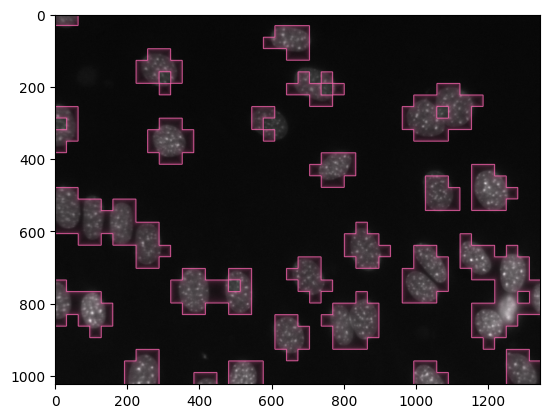

In [13]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))
plt.show()

The segmentation is patch-based, meaning the classifier assigns one label to each 32 × 32 patch rather than classifying individual pixels 

Therefore, the resulting segmentation has block-like boundaries and does not perfectly follow the contours of the cells

My theory on why some cells are not marked: there is less than 50% foreground in the patches of the cells, so they get discarded as a 0

**[Task 1.5.]()** Perform batch processing:

In [15]:
dice_scores = []

for i in [28, 29, 33, 44, 46, 49]:

    
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')

    
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png')
    gt = gt > 0

    
    seg = predict_image(img)

    
    dice = 2 * (seg & gt).sum() / (seg.sum() + gt.sum())

    dice_scores.append(dice)

    print(f'Image {i}: Dice = {dice}')


mean_dice = np.mean(dice_scores)

print('Mean Dice:', mean_dice)


Image 28: Dice = 0.7209812219847866
Image 29: Dice = 0.6600878826245624
Image 33: Dice = 0.6778978154021594
Image 44: Dice = 0.7125355936692934
Image 46: Dice = 0.6171491101827866
Image 49: Dice = 0.6889506296603939
Mean Dice: 0.6796003755873304


I use a for-loop to iterate over the six specified images 

For each image, I load the original image and its corresponding ground truth, then perform segmentation using the trained SVM 

I calculate the Dice coefficient by comparing the predicted segmentation with the ground truth 

Each score is stored in a list and printed 

Finally, I calculate the mean Dice coefficient to evaluate the overall segmentation performance

The SVM classifier achieves a higher mean Dice coefficient (0.680) than Otsu thresholding (0.547) 

This suggests that the supervised, patch-based classification approach provides better segmentation overall 

In particular, SVM improves segmentation on images 33, 44, and 46, where Otsu thresholding performs relatively poorly 

However, Otsu achieves higher Dice scores on images 28 and 49

This shows that the performance of both methods varies between images, but SVM provides better overall results for this dataset